# Hybrid Recommender — the baseline, and your changes
**MKTG 4604 · Fall 2026 · Group build**

**Group members:** *(replace with all names)*

This notebook is a working recommender for a small bookseller. It was written by hand, by someone without
AI, and it is deliberately basic. **It runs as given: upload the three CSV files and Run all.** Your job is
not to make it run; it is to decide what is wrong with it, change it, and show whether your change helped.

How to use it:

- **Part 0** audits the data. **Parts 1–3** are the baseline. Read them; don't rewrite them.
- **Part 4** is where you add your invented readers and judge what the baseline gives them.
- **Part 5** is where you make your changes — one at a time — and judge again.
- Comments marked `# CHOICE:` are decisions the baseline made for you, each with a question. The menu of
  changes at Part 5 starts from these.

**If you don't code:** Google Colab → upload the three CSVs (folder icon, left) → *Runtime → Run all*.
Read every printed table. Fill in the `people` list in Part 4 (it is a list, not code). You own the audit,
the readers, the hand verdicts, the case for each change, and the judgment. Coders own Part 5.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import dendrogram, linkage

pd.set_option('display.width', 160)

In [2]:
# The three files. ISBN is kept as text: some ISBNs end in 'X' and some start with 0.
book_data = pd.read_csv('book_data_sample_ed.csv',    dtype={'ISBN': str})
ratings   = pd.read_csv('ratings_data_sample_ed.csv', dtype={'ISBN': str})
users     = pd.read_csv('users_data_sample_ed.csv')

print('books', book_data.shape, '| ratings', ratings.shape, '| users', users.shape)

books (100, 12) | ratings (1221, 3) | users (1052, 3)


## Part 0 — What is in the data

Small organisation, data collected for other purposes, never cleaned. Read the output before you believe
anything the system says.

In [3]:
print('--- ratings ---')
print('rows:', len(ratings), '| readers:', ratings['User-ID'].nunique(), '| books rated:', ratings['ISBN'].nunique())
print('\nratings per reader:');  print(ratings.groupby('User-ID').size().describe().round(2))
print('\nhow often each rating value appears:'); print(ratings['Book-Rating'].value_counts().sort_index())
print('\n--- users ---')
print('rows:', len(users), '| age missing:', users['Age'].isna().sum())
print('age:'); print(users['Age'].describe().round(1))
print('\n--- books ---')
print('rows:', len(book_data), '| distinct ISBN:', book_data['ISBN'].nunique(), '| distinct titles:', book_data['title'].nunique())
print('\nmost-rated books:')
top5 = ratings['ISBN'].value_counts().head(5).rename('n_ratings').reset_index().rename(columns={'index': 'ISBN'})
print(top5.merge(book_data[['ISBN', 'title']].drop_duplicates('ISBN'), on='ISBN')[['title', 'n_ratings']].to_string(index=False))

--- ratings ---
rows: 1221 | readers: 1052 | books rated: 97

ratings per reader:
count    1052.00
mean        1.16
std         0.61
min         1.00
25%         1.00
50%         1.00
75%         1.00
max        14.00
dtype: float64

how often each rating value appears:
0     613
1       1
2       5
3       4
4       6
5      35
6      41
7      71
8     117
9     116
10    212
Name: Book-Rating, dtype: int64

--- users ---
rows: 1052 | age missing: 229
age:
count    823.0
mean      36.4
std       14.9
min        1.0
25%       27.0
50%       34.0
75%       45.0
max      239.0
Name: Age, dtype: float64

--- books ---
rows: 100 | distinct ISBN: 98 | distinct titles: 98

most-rated books:
                                                          title  n_ratings
                             the five people you meet in heaven        427
                                           the poisonwood bible         94
                                    little house on the prairie         65
     

**Audit (Paragraph A of your PDF starts here).** What is this data, and what does it mean for a system that
learns from "readers like you"? How much does a typical reader tell it? What is a rating of 0? What is wrong
with the ages? Is anything in the book file duplicated or mislabelled?

## Part 1 — Baseline: group the readers (collaborative filtering)

In [4]:
# One row per reader, one column per book, the rating in the cell.
# CHOICE: empty cells are filled with 0. The file also records 0 for "read, not rated".
#   Q: Should "never saw it" and "read it, didn't rate it" be the same number? What does that do to a
#      book's average?
def build_matrix(ratings, users):
    user_item = ratings.pivot_table(index='User-ID', columns='ISBN', values='Book-Rating', fill_value=0)
    ages = pd.to_numeric(users.set_index('User-ID').loc[user_item.index, 'Age'], errors='coerce')
    # CHOICE: missing ages are filled with the median age. Ages of 1 and 239 are kept.
    #   Q: Are those readers? What does keeping them do to the groups?
    ages = ages.fillna(ages.median())
    return user_item, ages

user_item, ages = build_matrix(ratings, users)

# Age is scaled (mean 0, spread 1) and appended as the last column, so readers are grouped on ratings AND age.
# CHOICE: age is ONE column beside the book columns; AGE_WEIGHT multiplies it.
#   Q: With about a hundred columns of ratings and one of age, which decides who lands together?
#      What should "readers like you" mean for this bookseller?
AGE_WEIGHT = 1.0

age_scaler = StandardScaler().fit(ages.to_frame())
features   = np.hstack([user_item.values, age_scaler.transform(ages.to_frame()) * AGE_WEIGHT])
n_items    = user_item.shape[1]
print('feature matrix:', features.shape, '= readers x (books + age)')

feature matrix: (1052, 98) = readers x (books + age)


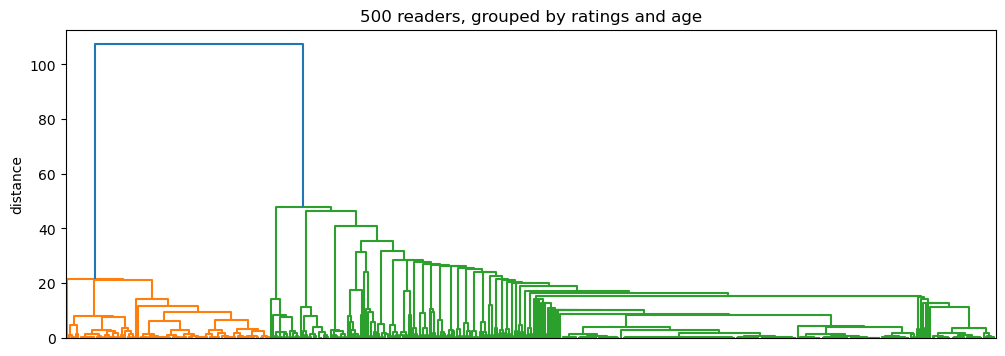

0    786
1    232
2     34
Name: readers, dtype: int64
         mean   min    max
Cluster                   
0        34.6   1.0  116.0
1        39.8  15.0  239.0
2        38.4  19.0   67.0

=== Group 0: 786 readers, 909 ratings ===
                             title   n  mean_rating
the five people you meet in heaven 192         0.14
       little house on the prairie  65         3.80
              the poisonwood bible  57         0.00
             to kill a mockingbird  44         4.27

=== Group 1: 232 readers, 258 ratings ===
                             title   n  mean_rating
the five people you meet in heaven 232         8.18
             to kill a mockingbird   5         7.40
              the poisonwood bible   3         0.00
                   the giving tree   2         4.50

=== Group 2: 34 readers, 54 ratings ===
                                           title  n  mean_rating
                            the poisonwood bible 34         8.26
              the five people you

In [5]:
# How many groups? Hierarchical clustering on a sample of 500 readers, read off the dendrogram.
sample = pd.DataFrame(features, index=user_item.index).sample(n=500, random_state=42)
plt.figure(figsize=(12, 4)); dendrogram(linkage(sample.values, method='ward'), no_labels=True)
plt.title('500 readers, grouped by ratings and age'); plt.ylabel('distance'); plt.show()

# CHOICE: K = 3 groups.
#   Q: Is that what the dendrogram shows? Could the bookseller act on more? On fewer?
K = 3
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(features)
reader_clusters = pd.DataFrame({'User-ID': user_item.index, 'Cluster': kmeans.labels_, 'Age': ages.values})

print(reader_clusters['Cluster'].value_counts().sort_index().rename('readers'))
print(reader_clusters.groupby('Cluster')['Age'].agg(['mean', 'min', 'max']).round(1))
for c in range(K):
    ids = reader_clusters.loc[reader_clusters.Cluster == c, 'User-ID']
    sub = ratings[ratings['User-ID'].isin(ids)]
    top = (sub.groupby('ISBN').agg(n=('User-ID', 'count'), mean_rating=('Book-Rating', 'mean'))
              .sort_values('n', ascending=False).head(4)
              .merge(book_data[['ISBN', 'title']].drop_duplicates('ISBN'), on='ISBN', how='left'))
    print(f'\n=== Group {c}: {len(ids)} readers, {len(sub)} ratings ===')
    print(top[['title', 'n', 'mean_rating']].round(2).to_string(index=False))

**For Paragraph A:** describe each group in one sentence a marketing manager would use. What are the
groups really separating on — taste, age, or one popular book?

## Part 2 — Baseline: from a group to a candidate list

In [6]:
# Which group does a reader belong to?
#   A KNOWN reader (in the data): read it off reader_clusters.
#   A STRANGER (age only): build a row with every book column 0 and the age in the age column, and ask k-means.
#   Q: Try several ages for a stranger. Does the group change? What does the baseline know about a new reader?
def group_of(age=None, user_id=None):
    if user_id is not None:
        return int(reader_clusters.loc[reader_clusters['User-ID'] == user_id, 'Cluster'].iloc[0])
    vec = np.zeros(n_items + 1)
    vec[n_items] = age_scaler.transform([[age]])[0, 0] * AGE_WEIGHT
    return int(kmeans.predict([vec])[0])

for a in [19, 30, 45, 60]:
    print(f'stranger aged {a} -> group {group_of(age=a)}')

stranger aged 19 -> group 0
stranger aged 30 -> group 0
stranger aged 45 -> group 0
stranger aged 60 -> group 0


/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [7]:
# The CANDIDATE list: the 25 books the reader's group rated highest.
# CHOICE: ranked by mean rating, ties broken by how many readers rated the book. Zeros count as ratings.
#   Q: Look at rating_count for the top five. How many readers is each "best book" based on?
#      Would you trust a restaurant with one five-star review over one with four hundred four-star reviews?
def candidate_list(group, n=25):
    ids = reader_clusters.loc[reader_clusters.Cluster == group, 'User-ID']
    sub = ratings[ratings['User-ID'].isin(ids)]
    agg = (sub.groupby('ISBN').agg(mean_rating=('Book-Rating', 'mean'), rating_count=('User-ID', 'count'))
              .reset_index()
              .sort_values(['mean_rating', 'rating_count'], ascending=False)
              .head(n))
    return agg.merge(book_data.drop_duplicates('ISBN'), on='ISBN', how='left')   # one ISBN is duplicated in the book file

candidate_list(group_of(age=30))[['title', 'mean_rating', 'rating_count']].head(10)

/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,title,mean_rating,rating_count
0,"oh, the places you'll go!",10.0,2
1,"cold night, brittle light",10.0,2
2,1984,10.0,2
3,where the sidewalk ends 30th anniversary speci...,10.0,1
4,harry potter and the goblet of fire (harry pot...,10.0,1
5,the outsiders,10.0,1
6,animal farm,10.0,1
7,brave new world,9.0,2
8,don quixote,9.0,1
9,gifts of the nile: ancient egyptian faience,9.0,1


## Part 3 — Baseline: re-rank the candidates by the book the reader liked (content-based filtering)

Every book becomes a vector: its genres (one column each), the words of its description (TF-IDF), its
average rating and year (scaled 0–1). Two books are similar when their vectors point the same way
(cosine similarity). The 25 candidates are sorted by similarity to the one book the reader said they liked.

In [8]:
books = book_data.drop_duplicates('ISBN').reset_index(drop=True)
books['genre_list'] = books['genres'].apply(ast.literal_eval)

genre_matrix = MultiLabelBinarizer().fit_transform(books['genre_list'])
desc_matrix  = TfidfVectorizer(stop_words='english').fit_transform(books['description'].fillna('')).toarray()
num_matrix   = MinMaxScaler().fit_transform(books[['av_rating', 'Year-Of-Publication']].fillna(0))

# CHOICE: the three blocks are stacked with equal weight. Genres: ~30 columns. Description words: ~3,000. Numbers: 2.
#   Q: Which block do you think actually decides similarity here? How would you check?
book_vectors = np.hstack([genre_matrix, desc_matrix, num_matrix])
sim_df = pd.DataFrame(cosine_similarity(book_vectors), index=books['title'], columns=books['title'])

def similarity_to(liked_book):
    s = sim_df[liked_book].drop(index=liked_book).reset_index()
    s.columns = ['title', 'similarity']
    return s

similarity_to('the hobbit').sort_values('similarity', ascending=False).head(5)

,title,similarity
69,the fellowship of the ring (the lord of the ri...,0.806008
9,the lord of the rings,0.804991
45,"the lion, the witch and the wardrobe",0.679086
27,alice's adventures in wonderland,0.678661
56,where the wild things are,0.669537


In [9]:
# THE RECOMMENDER. One function, two ways to call it:
#   recommend('the hobbit', age=19)         a stranger: placed in a group by age alone
#   recommend('the hobbit', user_id=9001)   a known reader: served from their own group
# Every call is logged (Part 4).
recommendation_log = []

def recommend(liked_book, age=None, user_id=None, n=10):
    group = group_of(age=age, user_id=user_id)
    cands = candidate_list(group)
    out   = (cands.merge(similarity_to(liked_book), on='title', how='inner')
                  .sort_values('similarity', ascending=False).head(n).copy())
    # CHOICE: the reason is a template sentence.  Q: Would a reader believe it? What would a better one say?
    genres = out['title'].map(books.set_index('title')['genre_list'])
    out['reason'] = genres.apply(lambda g: f"readers in your group rated it well; shares {g[0].lower() if isinstance(g, list) and g else 'a genre'} with your pick")
    recommendation_log.append({'when': pd.Timestamp.now(), 'liked_book': liked_book, 'age': age, 'user_id': user_id,
                               'group': group, 'shown': list(out['title']), 'version': MODEL_VERSION})
    return out[['title', 'Book-Author', 'mean_rating', 'rating_count', 'similarity', 'reason']].reset_index(drop=True)

MODEL_VERSION = 'baseline'
recommend('the hobbit', age=19)

/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,title,Book-Author,mean_rating,rating_count,similarity,reason
0,the lord of the rings,J. R. R. Tolkien,5.400000,5,0.804991,readers in your group rated it well; shares fa...
1,alice's adventures in wonderland,Lewis Carroll,5.666667,3,0.678661,readers in your group rated it well; shares cl...
2,harry potter and the goblet of fire (harry pot...,J. K. Rowling,10.000000,1,0.584723,readers in your group rated it well; shares fa...
3,the little prince,Antoine de Saint-ExupÃ©ry,6.181818,11,0.577835,readers in your group rated it well; shares cl...
4,the hitchhiker's guide to the galaxy,Douglas Adams,9.000000,1,0.576335,readers in your group rated it well; shares sc...
5,"oh, the places you'll go!",Seuss,10.000000,2,0.569824,readers in your group rated it well; shares ch...
6,the giving tree,Shel Silverstein,5.636364,33,0.529381,readers in your group rated it well; shares ch...
7,where the sidewalk ends 30th anniversary speci...,Shel Silverstein,10.000000,1,0.475938,readers in your group rated it well; shares po...
8,the count of monte cristo,Alexandre Dumas,6.250000,4,0.473498,readers in your group rated it well; shares cl...
9,little women,Louisa May Alcott,7.000000,4,0.470843,readers in your group rated it well; shares cl...


In [17]:
{'name': 'Greyson', 'age': 55, 'books': [('the diary of a young girl', 6), ('jane eyre', 7), ('little women', 9)]},
recommend('little women', age=55)

/Users/justin/anaconda3/lib/python3.11/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,title,Book-Author,mean_rating,rating_count,similarity,reason
0,the count of monte cristo,Alexandre Dumas,6.250000,4,0.682934,readers in your group rated it well; shares cl...
1,anne of green gables,Lucy Maud Montgomery,6.000000,1,0.575328,readers in your group rated it well; shares cl...
2,alice's adventures in wonderland,Lewis Carroll,5.666667,3,0.570040,readers in your group rated it well; shares cl...
3,of mice and men,John Steinbeck,8.250000,4,0.566458,readers in your group rated it well; shares cl...
4,don quixote,Miguel De Cervantes Saavedra,9.000000,1,0.565398,readers in your group rated it well; shares cl...
5,where the sidewalk ends 30th anniversary speci...,Shel Silverstein,10.000000,1,0.473661,readers in your group rated it well; shares po...
6,the little prince,Antoine de Saint-ExupÃ©ry,6.181818,11,0.472944,readers in your group rated it well; shares cl...
7,1984,George Orwell,10.000000,2,0.467202,readers in your group rated it well; shares cl...
8,brave new world,Aldous Huxley,9.000000,2,0.464249,readers in your group rated it well; shares cl...
9,animal farm,George Orwell,10.000000,1,0.463802,readers in your group rated it well; shares cl...


## Part 4 — Your readers, and the baseline's verdict (Paragraph A ends here; Paragraph B starts)

Your group invented ten readers on the individual pages. Add them all here. **They are test readers, not
new data** — ten people with three ratings each will not change what the model learned from a thousand.
They are how you find out what it does.

Fill the list below. **Titles must be copied exactly from the `title` column of the book file**
(lower case, as printed there). Ratings 1–10. Keep the one rated highest as the book they "liked".

In [10]:
people = [
    # {'name': 'Priya',  'age': 19, 'books': [('the hobbit', 9), ('1984', 7), ('the little prince', 8)]},
    # {'name': 'Marcus', 'age': 52, 'books': [('green eggs and ham (i can read it all by myself beginner books)', 10), ('the cat in the hat', 10), ('where the wild things are', 9)]},
    # ... ten entries: two per group member.
]

def add_people(people, start_id=9001):
    """Add invented readers to users and ratings. Looks each title up in the catalogue; reports what it found."""
    global ratings, users
    title_to_isbn = books.set_index('title')['ISBN'].to_dict()
    new_users, new_ratings, ids = [], [], {}
    for i, p in enumerate(people):
        uid = start_id + i; ids[p['name']] = uid
        new_users.append({'User-ID': uid, 'Location': 'test reader', 'Age': p['age']})
        found = 0
        for title, r in p['books']:
            if title in title_to_isbn:
                new_ratings.append({'User-ID': uid, 'ISBN': title_to_isbn[title], 'Book-Rating': r}); found += 1
            else:
                print(f"  !! {p['name']}: '{title}' is not in the catalogue — copy the title exactly from the book file")
        print(f"{p['name']} added as user {uid}: {found} of {len(p['books'])} titles found")
    users   = pd.concat([users[~users['User-ID'].isin(ids.values())],     pd.DataFrame(new_users)],   ignore_index=True)
    ratings = pd.concat([ratings[~ratings['User-ID'].isin(ids.values())], pd.DataFrame(new_ratings)], ignore_index=True)
    return ids

if people:
    person_ids = add_people(people)
    # Re-run Parts 1–2 so your readers have groups.  (Everything the baseline does, in one call.)
    user_item, ages = build_matrix(ratings, users)
    age_scaler = StandardScaler().fit(ages.to_frame())
    features   = np.hstack([user_item.values, age_scaler.transform(ages.to_frame()) * AGE_WEIGHT])
    n_items    = user_item.shape[1]
    kmeans     = KMeans(n_clusters=K, random_state=42, n_init=10).fit(features)
    reader_clusters = pd.DataFrame({'User-ID': user_item.index, 'Cluster': kmeans.labels_, 'Age': ages.values})
    for name, uid in person_ids.items():
        print(f'{name}: group {group_of(user_id=uid)}')

**Judge the baseline.** Pick five of your ten readers (one per member; at least two of them traps). For each,
run the two lines below, print the ten, and give every recommendation one letter: **S** sensible for this
person · **O** obvious (they would have found it anyway, or already have it) · **W** wrong. Fifty letters.
Write the five lines of the verdict table in your PDF; the counts go in the ladder.

In [11]:
# Example — replace with your five:
# recommend('the hobbit', user_id=person_ids['Priya'])        # as a known reader
# recommend('the hobbit', age=19)                              # the same person as a stranger — is it different?

def distinct_titles(names):
    """How many different books appear across these readers' latest lists (out of 10 x readers)."""
    shown = [row['shown'] for row in recommendation_log if row['user_id'] in [person_ids[n] for n in names] and row['version'] == MODEL_VERSION]
    return len({t for lst in shown for t in lst}), 10 * len(shown)

## Part 5 — Your changes (Paragraphs B and C)

**The rule: change one thing, re-run your five readers, judge, keep or throw away. Then the next.** Three
changes at once with one before/after tells you nothing about which one worked.

**The menu** (start anywhere; add your own):
1. **Swap the order** — content-based first across the whole catalogue, then the group's ratings to re-rank.
2. **Fix the ranking** — a minimum rating count, or a Bayesian average that shrinks a book's mean toward the global mean when few people rated it.
3. **Treat 0 as "read, unrated"** — leave it out of the means.
4. **Age bands instead of k-means** (<25, 25–45, 45+) — did the clustering earn its keep?
5. **Raise `AGE_WEIGHT`** — or lower it to zero.
6. **Item-based** — books that people who liked *this* book were unusually likely to also like.
7. **A diversity cap** — no more than three books from one genre in the ten.
8. **Better reasons** — a real sentence per book, written by rule or by an AI model from the titles and genres.
9. **Treat strangers differently** — the baseline places a new reader by age alone; what else could it use?

For each change: set `MODEL_VERSION` to a short name, rewrite the function it touches (copy it below, don't
edit the baseline), re-run your five readers, count S/O/W and distinct titles, decide. A change you tried and
**rejected** counts in your favour in the trace if you say why.

In [12]:
# ---- Change 1 ----
MODEL_VERSION = 'change-1: <name it>'
# redefine the function(s) this change touches here, then re-run your five readers and judge

In [13]:
# ---- Change 2 ----
MODEL_VERSION = 'change-2: <name it>'

In [14]:
# ---- Change 3 (if any) ----
MODEL_VERSION = 'change-3: <name it>'

## Before and after

For the PDF: the **ladder** (one row per change you kept: name · S/O/W counts across the fifty · distinct
titles of 50) and the **before/after table** (five readers × ten titles, baseline beside final). The cell
below prints the log so you can build both from it.

In [15]:
log = pd.DataFrame(recommendation_log)
log[['version', 'user_id', 'age', 'liked_book', 'shown']] if len(log) else print('no recommendations logged yet')

,version,user_id,age,liked_book,shown
0,baseline,None,19,the hobbit,"[the lord of the rings, alice's adventures in ..."


## Paragraph C — Judgment, and the trace

Did your changes help, by your fifty letters and your distinct-titles count? What can this test *not* tell
you — and what would the bookseller have to collect to find out? (It can only reward books your five readers
would already have liked. What kind of good recommendation can it never give credit for?)

**The trace** goes at the end of your PDF: 3–6 rows — *what we asked the AI tool · what it gave us · what we
checked · what we changed* — including changes you tried and threw away. You may ask the tool to help write
it. You may not let it be the only one who read it.